# Toxicidade e conteúdo explícito das letras

**Parte pesada: rodar em GPU.** Em CPU leva horas; em GPU, poucos minutos. O resultado vai para
`dados/toxicidade.csv` (só escores, sem letra), que o `pipelineDifusao.ipynb` usa.

Usa **apenas o `finalData.csv`** (top 40 anual dos 6 países com letra); nenhum outro mercado entra.

O que este notebook mede:

1. **Toxicidade da letra original** com o Detoxify `multilingual` (XLM-R). A letra original é usada porque a
   tradução suaviza gírias e palavrões.
2. **Toxicidade da letra traduzida** com o Detoxify `unbiased` (RoBERTa, inglês). Serve para (a) medir o japonês,
   que não está entre as línguas de treino do modelo multilíngue, e (b) quantificar quanto a tradução suaviza.
3. **Validação** contra a flag `explicit` do Spotify (MGDplus, disponível para as faixas de 2017–2021).
4. Toxicidade por país e ano, e se ela está **convergindo** entre os países.

**Ressalvas que precisam ir para o texto:**
- O Detoxify foi treinado em **comentários de internet**, não em letras. Metáforas ("kill it", "matar a saudade")
  geram falsos positivos, e gírias regionais (funk, reggaeton) podem passar despercebidas. Por isso a validação
  contra `explicit` vem antes de qualquer conclusão.
- O modelo multilíngue foi treinado em en, es, pt, fr, it, ru e tr. Para **japonês** (e outras línguas) usamos
  o escore da tradução: é a coluna `tox` (escore principal).
- Toxicidade é conteúdo explícito/ofensivo na letra, não "comportamento antissocial" de pessoas.

Para testar rápido em CPU: `TOX_LIMITE=20` processa só 20 faixas. O cache em `dados/cache/` permite interromper e
continuar de onde parou.

In [1]:
import os, hashlib, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import roc_auc_score
from IPython.display import display

from comum import (PASTA_RES, PASTA_CACHE, PAISES, NOMES, COR, SEQ, aplica_estilo, plota_matriz, tendencia,
                   carrega_letras, idioma_simples, datas_lancamento)

warnings.filterwarnings("ignore", category=FutureWarning)
aplica_estilo()

MODELO_ORIG = os.environ.get("TOX_MODELO", "multilingual")   # letra original
MODELO_TRAD = os.environ.get("TOX_MODELO_EN", "unbiased")    # letra traduzida (inglês)
BATCH       = int(os.environ.get("TOX_BATCH", 16))
LIMITE      = int(os.environ.get("TOX_LIMITE", 0))           # > 0: só as N primeiras faixas (teste)
MAX_TOK     = 400                                            # limite do modelo é 512 tokens
LIMIAR      = 0.5                                            # trecho "tóxico"
LINGUAS_MULTI = {"en", "es", "pt"}                           # línguas do treino do multilíngue presentes nos dados
ARQ_TOX     = PASTA_CACHE.parent / "toxicidade.csv"
PASTA_CACHE.mkdir(parents=True, exist_ok=True)
PASTA_RES.mkdir(exist_ok=True)

d = carrega_letras()                                            # finalData.csv (top 40 anual, 6 países)
d = d[d["cc"].isin(PAISES) & (d["letra_limpa"].str.len() >= 30)]
print("países no escopo:", " ".join(sorted(d["cc"].unique())), "| anos", d["year"].min(), "-", d["year"].max())
faixas = d.drop_duplicates("track_id").set_index("track_id")[["title", "artists", "chave", "idioma", "letra_limpa", "letra_en_limpa"]]
faixas["idioma"] = faixas["idioma"].map(idioma_simples)
if LIMITE:
    faixas = faixas.iloc[:LIMITE]
    print(f"MODO TESTE: só {LIMITE} faixas")
print(f"{len(faixas)} faixas | idiomas: {faixas['idioma'].value_counts().to_dict()}")

países no escopo: au br es jp mx us | anos 2017 - 2025
1446 faixas | idiomas: {'es': 494, 'en': 448, 'pt': 320, 'ja': 177, 'outro': 4, 'ko': 3}


## 1. Escores

Cada letra é dividida em trechos de até 400 tokens (respeitando as quebras de linha). Por música, guardamos a
**média** dos trechos (ponderada pelo tamanho) e o **máximo** (a música tem pelo menos um trecho pesado?).

In [2]:
def divide_trechos(texto, tok, max_tok):
    linhas = [l for l in str(texto).split("\n") if l.strip()]
    trechos, atual, n = [], [], 0
    for l in linhas:
        k = len(tok.tokenize(l)) + 1
        if atual and n + k > max_tok:
            trechos.append("\n".join(atual)); atual, n = [], 0
        atual.append(l); n += k
    if atual:
        trechos.append("\n".join(atual))
    return trechos or [str(texto)]


_modelos = {}

def carrega_detoxify(tipo):
    if tipo not in _modelos:
        import torch
        from detoxify import Detoxify
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        _modelos[tipo] = Detoxify(tipo, device=dev)
        print(f"Detoxify '{tipo}' em {dev} | classes: {_modelos[tipo].class_names}")
    return _modelos[tipo]


def pontua(textos: pd.Series, tipo: str, nome: str, bloco=100) -> pd.DataFrame:
    """Escores por música (index = track_id). Cache por track_id + hash do texto, salvo a cada `bloco` músicas."""
    arq = PASTA_CACHE / f"tox_{nome}_{tipo}.csv"
    textos = textos.dropna()
    chaves = pd.Series([f"{t}:{hashlib.md5(x.encode('utf-8')).hexdigest()[:10]}" for t, x in textos.items()], index=textos.index)
    cache = pd.read_csv(arq).set_index("chave") if arq.exists() else pd.DataFrame()
    falta = [t for t in textos.index if chaves[t] not in cache.index]
    if falta:
        m = carrega_detoxify(tipo)
        t0 = time.time()
        for ini in range(0, len(falta), bloco):
            lote = falta[ini:ini + bloco]
            trechos, dono, ntok = [], [], []
            for t in lote:
                for b in divide_trechos(textos[t], m.tokenizer, MAX_TOK):
                    trechos.append(b); dono.append(t); ntok.append(len(m.tokenizer.tokenize(b)))
            ordem = np.argsort(ntok)                      # lotes de tamanho parecido = menos padding
            esc = {c: np.empty(len(trechos)) for c in m.class_names}
            for i in range(0, len(ordem), BATCH):
                ix = ordem[i:i + BATCH]
                out = m.predict([trechos[j] for j in ix])
                for c in m.class_names:
                    esc[c][ix] = np.asarray(out[c], dtype=float)
            df = pd.DataFrame({"track_id": dono, "ntok": ntok, **esc})
            linhas = []
            for t, g in df.groupby("track_id", sort=False):
                r = {"chave": chaves[t], "track_id": t, "trechos": len(g)}
                for c in m.class_names:
                    r[f"{c}_media"] = np.average(g[c], weights=g["ntok"])
                    r[f"{c}_max"] = g[c].max()
                linhas.append(r)
            novo = pd.DataFrame(linhas).set_index("chave")
            cache = pd.concat([cache, novo])
            cache.to_csv(arq)
            feitos = min(ini + bloco, len(falta))
            print(f"[{nome}/{tipo}] {feitos}/{len(falta)} músicas | {time.time() - t0:.0f}s")
    else:
        print(f"[{nome}/{tipo}] {len(textos)} músicas lidas do cache {arq.name}")
    out = cache.loc[chaves.values].set_index("track_id")
    return out.drop(columns=["trechos"])


tox_o = pontua(faixas["letra_limpa"], MODELO_ORIG, "original").add_prefix("orig_")
tox_e = pontua(faixas["letra_en_limpa"], MODELO_TRAD, "traduzida").add_prefix("en_")
tox = faixas[["title", "artists", "chave", "idioma"]].join(tox_o).join(tox_e)

# escore principal: letra original quando o modelo multilíngue cobre a língua; senão, a tradução
tox["tox"] = np.where(tox["idioma"].isin(LINGUAS_MULTI), tox["orig_toxicity_media"], tox["en_toxicity_media"])
tox["tox_max"] = np.where(tox["idioma"].isin(LINGUAS_MULTI), tox["orig_toxicity_max"], tox["en_toxicity_max"])
tox["toxica"] = tox["tox_max"] >= LIMIAR
tox["fonte_tox"] = np.where(tox["idioma"].isin(LINGUAS_MULTI), f"original/{MODELO_ORIG}", f"traduzida/{MODELO_TRAD}")

_, explicit = datas_lancamento()
tox["explicit"] = tox.index.map(explicit)
print(f"flag explicit do Spotify disponível para {tox['explicit'].notna().mean():.0%} das faixas")
display(tox.groupby("idioma")[["tox", "tox_max", "toxica"]].mean().round(3))

/home/besome/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|    | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|█| 201/201 [00:00<00:00, 122

Detoxify 'multilingual' em cpu | classes: ['toxicity', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'sexual_explicit']


[original/multilingual] 100/146 músicas | 105s


[original/multilingual] 146/146 músicas | 157s
Downloading: "https://github.com/unitaryai/detoxify/releases/download/v0.3-alpha/toxic_debiased-c7548aa0.ckpt" to /home/besome/.cache/torch/hub/checkpoints/toxic_debiased-c7548aa0.ckpt


... (241 outputs left out)

[traduzida/unbiased] 1400/1446 músicas | 1463s


[traduzida/unbiased] 1446/1446 músicas | 1509s


flag explicit do Spotify disponível para 67% das faixas


,tox,tox_max,toxica
idioma,,,
en,0.351,0.419,0.422
es,0.419,0.505,0.510
ja,0.161,0.229,0.220
ko,0.034,0.059,0.000
outro,0.075,0.109,0.000
pt,0.457,0.525,0.541


## 2. Validação contra a flag `explicit` do Spotify

AUC = probabilidade de uma faixa marcada como explícita ter escore maior que uma não marcada (0,5 = acaso).
A flag do Spotify é declarada pelas gravadoras e cobre palavrão e conteúdo sexual/violento. Não é um gabarito
perfeito, mas é independente do modelo.

In [3]:
val = tox.dropna(subset=["explicit"]).copy()
val["explicit"] = val["explicit"].astype(str).str.lower().isin(["true", "1"])
linhas = []
for idi, g in [("todas", val)] + list(val.groupby("idioma")):
    if g["explicit"].nunique() < 2 or len(g) < 20:
        continue
    r = {"idioma": idi, "n": len(g), "% explicit": g["explicit"].mean() * 100}
    for col in ["tox", "tox_max", "orig_toxicity_media", "orig_toxicity_max", "en_toxicity_media", "en_toxicity_max",
                "orig_obscene_max", "en_obscene_max"]:
        if col in g and g[col].notna().all():
            r[f"AUC {col}"] = roc_auc_score(g["explicit"], g[col])
    linhas.append(r)
validacao = pd.DataFrame(linhas)
display(validacao.round(3))

,idioma,n,% explicit,AUC tox,AUC tox_max,AUC orig_toxicity_media,AUC orig_toxicity_max,AUC en_toxicity_media,AUC en_toxicity_max,AUC orig_obscene_max,AUC en_obscene_max
0,todas,973,23.741,0.835,0.860,0.849,0.873,0.874,0.877,0.904,0.900
1,en,331,46.828,0.948,0.952,0.948,0.952,0.936,0.938,0.968,0.958
2,es,301,16.279,0.713,0.723,0.713,0.723,0.757,0.755,0.753,0.782
3,ja,136,0.735,0.874,0.837,0.437,0.430,0.874,0.837,0.015,0.948
4,pt,200,13.000,0.766,0.839,0.766,0.839,0.855,0.868,0.852,0.880


## 3. A tradução suaviza a toxicidade?

Mesmas músicas, escore na letra original (modelo multilíngue) × na tradução (modelo em inglês). Para músicas
originalmente em inglês, a "tradução" é a própria letra, então a diferença ali mede só a troca de modelo
(serve de linha de base).

In [4]:
linhas = []
for idi, g in tox.groupby("idioma"):
    g = g.dropna(subset=["orig_toxicity_media", "en_toxicity_media"])
    if len(g) < 10:
        continue
    dif = g["en_toxicity_media"] - g["orig_toxicity_media"]
    linhas.append({"idioma": idi, "n": len(g), "original (multi)": g["orig_toxicity_media"].mean(),
                   "traduzida (en)": g["en_toxicity_media"].mean(), "diferença média": dif.mean(),
                   "p (Wilcoxon)": wilcoxon(dif).pvalue if (dif != 0).any() else np.nan,
                   "Spearman": spearmanr(g["orig_toxicity_media"], g["en_toxicity_media"])[0]})
traducao = pd.DataFrame(linhas)
display(traducao.round(4))

,idioma,n,original (multi),traduzida (en),diferença média,p (Wilcoxon),Spearman
0,en,448,0.3513,0.3532,0.0019,0.028,0.9381
1,es,494,0.4186,0.3003,-0.1183,0.000,0.7933
2,ja,177,0.0015,0.1609,0.1594,0.000,0.0761
3,pt,320,0.4566,0.2659,-0.1907,0.000,0.6533


## 4. Toxicidade por país e ano

Cada célula (país, ano) é o top 40 anual daquele país. Mostramos a fração de músicas com algum trecho tóxico
(`tox_max ≥ 0,5`) e o escore médio. **Convergência** = o desvio-padrão entre os países cai ao longo dos anos.

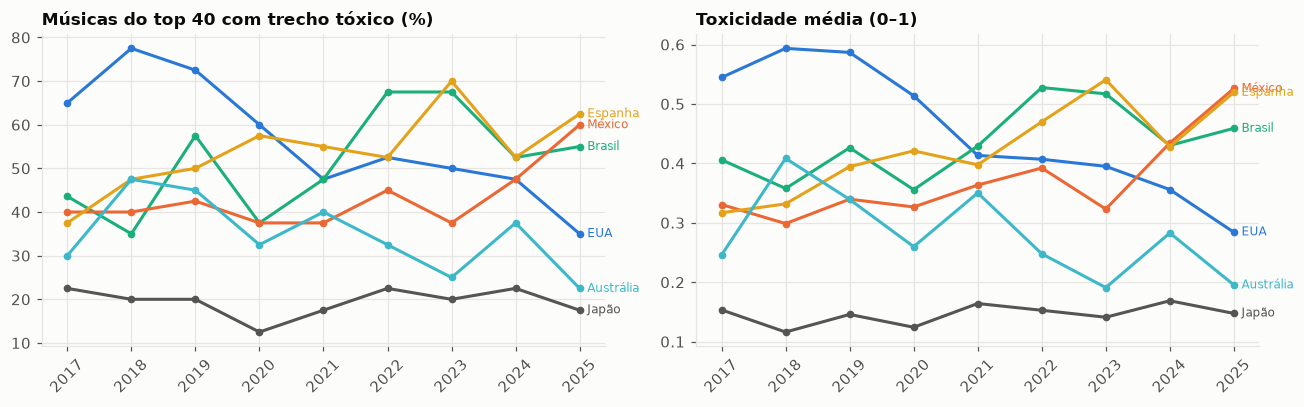

Tendência da fração de músicas tóxicas por país (pontos percentuais/100 por ano):


,inclinacao,ic95_lo,ic95_hi,p
us,-0.0438,-0.0642,-0.0233,0.0015
br,0.0247,-0.0067,0.0561,0.1056
mx,0.0167,-0.0018,0.0351,0.0700
es,0.0250,0.0050,0.0450,0.0214
au,-0.0167,-0.0401,0.0068,0.1371
jp,-0.0004,-0.0110,0.0102,0.9286


Convergência (inclinação < 0 = países ficando mais parecidos em toxicidade):


,inclinacao,ic95_lo,ic95_hi,p
dp_tox,0.0006,-0.0072,0.0084,0.8540
dp_pct,0.0007,-0.0096,0.0111,0.8718
dp_tox_H1,-0.0047,-0.0157,0.0062,0.3419


In [5]:
dd = d[["cc", "year", "track_id"]].merge(tox[["tox", "tox_max", "toxica", "explicit", "idioma"]], left_on="track_id", right_index=True)
cel = dd.groupby(["cc", "year"]).agg(tox=("tox", "mean"), pct_toxicas=("toxica", "mean"), n=("tox", "size")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cores = dict(zip(PAISES, [COR["s1"], COR["s3"], COR["s2"], "#e3a21a", "#3cb8c9", "#555555"]))
for ax, col, tit in [(axes[0], "pct_toxicas", "Músicas do top 40 com trecho tóxico (%)"), (axes[1], "tox", "Toxicidade média (0–1)")]:
    for cc in PAISES:
        g = cel[cel["cc"] == cc]
        y = g[col] * (100 if col == "pct_toxicas" else 1)
        ax.plot(g["year"], y, color=cores[cc], marker="o", markersize=4)
        if len(g):
            ax.annotate(NOMES[cc], (g["year"].iloc[-1], y.iloc[-1]), xytext=(5, 0), textcoords="offset points",
                        fontsize=8, color=cores[cc], va="center")
    ax.set_title(tit, loc="left"); ax.set_xticks(sorted(cel["year"].unique())); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(PASTA_RES / "toxicidade_paises.png"); plt.show()

t_pais = pd.DataFrame({cc: tendencia(*cel[cel["cc"] == cc][["year", "pct_toxicas"]].T.values) for cc in PAISES}).T
print("Tendência da fração de músicas tóxicas por país (pontos percentuais/100 por ano):")
display(t_pais.round(4))

disp = cel.groupby("year").agg(dp_tox=("tox", "std"), dp_pct=("pct_toxicas", "std")).reset_index()
h1 = cel[cel["cc"].isin(["us", "br", "mx", "es"])].groupby("year").agg(dp_tox_H1=("tox", "std")).reset_index()
disp = disp.merge(h1, on="year")
t_conv = pd.DataFrame({k: tendencia(disp["year"], disp[k]) for k in ["dp_tox", "dp_pct", "dp_tox_H1"]}).T
print("Convergência (inclinação < 0 = países ficando mais parecidos em toxicidade):")
display(t_conv.round(4))

In [6]:
# toxicidade por cluster semântico (se o pipelineAnalise já rodou)
arq_cl = PASTA_RES / "musicas_clusters.csv"
if arq_cl.exists():
    cl = pd.read_csv(arq_cl).drop_duplicates("track_id").set_index("track_id")["cluster"]
    por_cluster = tox.join(cl, how="inner").groupby("cluster").agg(n=("tox", "size"), tox=("tox", "mean"),
                                                                    pct_toxicas=("toxica", "mean"))
    print("Toxicidade por cluster (versão principal do pipelineAnalise):")
    display(por_cluster.round(3))

Toxicidade por cluster (versão principal do pipelineAnalise):


,n,tox,pct_toxicas
cluster,,,
0,489,0.279,0.319
1,151,0.661,0.768
2,394,0.471,0.579
3,185,0.162,0.184
4,225,0.384,0.524


In [7]:
saida = tox.drop(columns=["title", "artists"]).reset_index()
saida.to_csv(ARQ_TOX, index=False)
validacao.to_csv(PASTA_RES / "toxicidade_validacao_explicit.csv", index=False)
traducao.to_csv(PASTA_RES / "toxicidade_original_x_traducao.csv", index=False)
cel.to_csv(PASTA_RES / "toxicidade_por_pais_ano.csv", index=False)
t_conv.to_csv(PASTA_RES / "toxicidade_convergencia.csv")
print(f"escores salvos em {ARQ_TOX} ({len(saida)} faixas)")
if len(validacao):
    v = validacao.set_index("idioma")
    print("AUC do escore principal contra 'explicit':", v["AUC tox"].round(2).to_dict() if "AUC tox" in v else "—")
for k, t in t_conv.iterrows():
    print(f"  {k:<10} {t['inclinacao']:+.4f}/ano [IC95% {t['ic95_lo']:+.4f}, {t['ic95_hi']:+.4f}] p={t['p']:.3f}")

escores salvos em /home/besome/codigo/so/compSocial/SocialComp/dados/toxicidade.csv (1446 faixas)
AUC do escore principal contra 'explicit': {'todas': 0.84, 'en': 0.95, 'es': 0.71, 'ja': 0.87, 'pt': 0.77}
  dp_tox     +0.0006/ano [IC95% -0.0072, +0.0084] p=0.854
  dp_pct     +0.0007/ano [IC95% -0.0096, +0.0111] p=0.872
  dp_tox_H1  -0.0047/ano [IC95% -0.0157, +0.0062] p=0.342
